# Identifikation von Solaranlagen in Luftbildern

Dieses Notebook enthält das gesamte Projekt: Datenvorbereitung, Modelle, Training, Evaluation und Erklärung, von offenen Daten bis zum gewählten Arbeitspunkt. Es benötigt keine weiteren Projektdateien.

**Aufbau.** Jeder Schritt beantwortet eine Frage, und die Antwort begründet den nächsten Schritt.

1. Können die Ergebnisse von DeepSolaris reproduziert werden? Welche Leistung erbringt das Modell in NRW, und wo liegen die Schwachstellen?
2. Bleiben die Schwachstellen erhalten, wenn das Modell an Daten aus NRW neu trainiert wird?
3. Sind die Schwachstellen durch die Art der Überwachung bedingt (ein Label je Kachel statt je Pixel)?
4. Worauf stützt sich eine Entscheidung: auf die Anlage, auf ein anlagenähnliches Objekt oder auf die Umgebung?
5. Verallgemeinert eine Architektur für feine Details im Kontext (U-Net++) besser auf unbekannte Dächer?
6. Findet eine Verlustfunktion, die jede Anlage gleich gewichtet, mehr kleine Anlagen, und ist der Gewinn über Startwerte stabil?
7. Welchen Arbeitspunkt sollte ein statistisches Amt wählen?

**Regeln für jeden Vergleich.**

* Gleicher Encoder (ResNet50), gleiche Ausschnitte, gleiche räumliche Aufteilung, gleiche Augmentierung.
* Gleiche Fehlalarmquote: Jedes Modell erhält die Schwelle, die 30 Fehlalarme je 1 000 Validierungsausschnitte ergibt. Ein Modell, das einfach öfter „Anlage“ sagt, kann so nicht besser aussehen.
* Die Testmenge wird nie zur Auswahl verwendet.
* Ergebnisse werden nach Teilgruppen aufgeschlüsselt, jeweils mit 95-%-Intervall.
* Die Übertragbarkeit wird auf niederländischen Kacheln geprüft, auf denen kein Modell trainiert wurde; die Schwelle bleibt dabei auf NRW festgelegt.

Jeder Schritt hat dieselbe Form: **Frage** → **Aufbau** → Code → Ergebnisse → **Was sich zeigte** und **Was es nicht zeigt**.

**Ausführung.** Auf einer Laptop-GPU (RTX 3070) dauert ein Lauf von Grund auf etwa 24 Stunden, den Großteil davon das Training von U-Net++. Trainierte Modelle liegen in `notebook_run/checkpoints/`; ist ein Checkpoint vorhanden, wird das Modell geladen statt neu trainiert, und das Notebook gibt das aus. `QUICK = True` führt die ganze Kette in wenigen Minuten auf einer kleinen Stichprobe aus, um zu prüfen, ob der Code läuft.

*Hinweis: Tabellen und Abbildungen wurden mit englischen Beschriftungen erzeugt (hit rate = Trefferquote, precision = Präzision, FA = Fehlalarme, NL = Niederlande).*

In [1]:
QUICK = False            # True: kleine Stichprobe, 1 Epoche, 2 Startwerte - prüft, ob jede Zelle läuft
SEEDS = [21, 7, 42]      # Startwerte für das wiederholte Modell (Schritt 6); die Aufteilung bleibt immer gleich
EPOCHS = 20

## Einrichtung

In [ ]:
import warnings
warnings.filterwarnings("ignore")      # Hinweise der Bibliotheken auf veraltete Funktionen 

import io
import json
import shutil
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from IPython.display import display
from PIL import Image
from scipy import ndimage
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from torchvision import models
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

if QUICK:
    EPOCHS, SEEDS = 1, SEEDS[:2]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DATA = Path.cwd().parent / "daten_extern"                    # alle heruntergeladenen Daten liegen hier
KIT_DIR, DOP_DIR, PATCHES = DATA / "kit", DATA / "dop", DATA / "patches"
NL_ZIP = DATA / "deepsolaris" / "DeepStat-WP5-dataset.zip"
WEIGHTS = DATA / "deepsolaris" / "solar_trained_ResNet50.pth"
RUN_DIR = Path.cwd() / ("notebook_run_quick" if QUICK else "notebook_run")
CKPT, SCORES = RUN_DIR / "checkpoints", RUN_DIR / "scores"
for d in (CKPT, SCORES):
    d.mkdir(parents=True, exist_ok=True)

SPLIT_SEED = 21          # die räumliche Aufteilung ist fest, zwischen Startwerten variiert nur der Trainingszufall
FA_TARGET = 30.0         # Fehlalarme je 1 000 Validierungsausschnitte: Budget für den Modellvergleich
FA_FINAL = 60.0          # Schritt 7: Budget für das gewählte Modell, vorab festgelegt
NL_PAD = 12              # niederländische Kacheln haben 200 px; U-Nets brauchen ein Vielfaches von 32 -> gespiegelt auf 224 auffüllen
AREA_BINS = [0, 5, 20, 50, 200, 1e9]                       # m2; bei 10 cm entspricht 1 m2 = 100 px
AREA_LABELS = ["under 5 m2", "5-20 m2", "20-50 m2", "50-200 m2", "over 200 m2"]
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

device: cuda NVIDIA GeForce RTX 3070 Laptop GPU


## Schritt 0 · Daten

Alle Daten sind frei verfügbar. Jeder Teil wird nur heruntergeladen oder erzeugt, wenn er noch nicht vorhanden ist.

- Masken der NRW-Solaranlagen: Krikau & Keller 2025; RADAR4KIT, DOI 10.35097/ggptxqgmqqczjp7v (CC BY-SA 4.0)
- Digitale Orthophotos NRW aus dem jeweils passenden Befliegungsjahr: opengeodata.nrw.de (dl-de/zero-2-0)
- DeepSolaris / DeepStat WP5: niederländische Bildkacheln, 200 px, Ja/Nein-Labels | Zenodo 7551799 (CC BY 4.0), 4 GB
- DeepSolaris-ResNet50-Gewichte | Zenodo 7547703

Die KIT-Masken müssen manuell heruntergeladen werden, nach `daten_extern/kit/` (Dateien `label_manual_nrw_*.tif`).

**Warum das Bildjahr wichtig ist.** Eine Maske, die auf dem Luftbild von 2022 gezeichnet wurde, muss mit dem Luftbild von 2022 gepaart werden. Auf einem neueren Bild würden seither gebaute Anlagen als Fehlalarme zählen, obwohl der Fehler in den Labels liegt.

**Warum die Ausschnitte einmalig geschnitten werden.** Eine JPEG2000-Kachel mit 10 000 × 10 000 px für jedes Trainingsbeispiel neu zu dekodieren ist viel zu langsam. Jede Kachel wird daher einmal dekodiert und in Ausschnitte von 256 × 256 px zerlegt (25,6 m, nahe an den 20-m-Kacheln von DeepSolaris). Behalten werden:

* jeder Ausschnitt mit mindestens 1 m² Anlagenfläche;
* zufällig 30 % der leeren Ausschnitte;
* nur Ausschnitte, die überwiegend innerhalb des Luftbilds liegen.

Die Maske wird per Nächster-Nachbar-Interpolation von 0,2 m auf 0,1 m gebracht, damit die Klassenwerte 0/1/2 erhalten bleiben.

In [3]:
DOP_BASE = "https://www.opengeodata.nrw.de/produkte/geobasis/lusat"
DOP_CURRENT_YEAR = 2025                 # die neueste Befliegung liegt in 'akt', ältere in 'hist'
NL_URL = "https://zenodo.org/records/7551799/files/DeepStat-WP5-dataset.zip?download=1"
WEIGHTS_URL = "https://zenodo.org/records/7547703/files/solar_trained_ResNet50.pth?download=1"


def download(url, dst):
    """Download mit Fortsetzung: Die Server brechen bei großen Dateien manchmal die Verbindung ab."""
    dst = Path(dst); dst.parent.mkdir(parents=True, exist_ok=True)
    if dst.exists():
        return dst
    tmp = dst.with_suffix(dst.suffix + ".part")
    for attempt in range(10):
        have = tmp.stat().st_size if tmp.exists() else 0
        try:
            req = urllib.request.Request(url, headers={"Range": f"bytes={have}-"} if have else {})
            with urllib.request.urlopen(req, timeout=120) as r, open(tmp, "ab" if have else "wb") as f:
                if have and r.status != 206:     # Server hat die Range-Anfrage ignoriert: von vorn beginnen
                    f.truncate(0)
                shutil.copyfileobj(r, f, 1 << 20)
            break
        except OSError as e:
            print(f"  retry {attempt + 1}: {e}"); time.sleep(5 * (attempt + 1))
    tmp.replace(dst)
    print(f"downloaded {dst.name} ({dst.stat().st_size / 1e6:.0f} MB)")
    return dst


def mask_key(path):
    """label_manual_nrw_0292_5653_2023.tif -> (292, 5653, 2023): linke untere Ecke in km, Bildjahr."""
    _, _, _, e, n, y = Path(path).stem.split("_")
    return int(e), int(n), int(y)


def dop_url(e, n, y):
    name = f"dop10rgbi_32_{e}_{n}_1_nw_{y}.jp2"
    if y == DOP_CURRENT_YEAR:
        return f"{DOP_BASE}/akt/dop/dop_jp2_f10/{name}"
    return f"{DOP_BASE}/hist/hist_dop/hist_dop_jp2_f10/hist_dop_{y}/epsg_25832/{name}"


def read_pair(dop_path, mask_path):
    """Luftbild (RGB) und Maske auf demselben 0,1-m-Raster."""
    import rasterio
    from rasterio.enums import Resampling
    from rasterio.windows import from_bounds
    with rasterio.open(dop_path) as src:
        img, bounds, shape = src.read([1, 2, 3]), src.bounds, (src.height, src.width)
    with rasterio.open(mask_path) as m:
        win = from_bounds(*bounds, transform=m.transform)
        mask = m.read(1, window=win, out_shape=shape, resampling=Resampling.nearest, boundless=True, fill_value=0)
    return np.moveaxis(img, 0, -1), mask.astype(np.uint8)


def build_patches(size=256, neg_share=0.3, seed=0, min_pv_px=100):
    rng = np.random.default_rng(seed)
    (PATCHES / "img").mkdir(parents=True, exist_ok=True); (PATCHES / "mask").mkdir(exist_ok=True)
    rows = []
    for mask_path in sorted(KIT_DIR.glob("label_manual_nrw_*.tif")):
        e, n, y = mask_key(mask_path)
        dop = download(dop_url(e, n, y), DOP_DIR / f"dop10rgbi_32_{e}_{n}_1_nw_{y}.jp2")
        img, mask = read_pair(dop, mask_path)
        H, W = mask.shape
        for r in range(0, H - size + 1, size):
            for c in range(0, W - size + 1, size):
                ip, mp = img[r:r + size, c:c + size], mask[r:r + size, c:c + size]
                n_roof, n_ground = int((mp == 1).sum()), int((mp == 2).sum())
                has_pv = n_roof + n_ground >= min_pv_px          # mindestens 1 m2 Anlagenfläche
                if not has_pv and rng.random() > neg_share:
                    continue
                if (ip == 0).all(axis=-1).mean() > 0.5:          # überwiegend außerhalb des Luftbilds
                    continue
                pid = f"{e}_{n}_{y}_{r:05d}_{c:05d}"
                Image.fromarray(ip).save(PATCHES / "img" / f"{pid}.png")
                Image.fromarray(mp).save(PATCHES / "mask" / f"{pid}.png")
                rows.append(dict(patch_id=pid, east_km=e, north_km=n, year=y, row=r, col=c,
                                 x=e * 1000 + (c + size / 2) * 0.1,              # Mittelpunkt des Ausschnitts, EPSG:25832
                                 y=(n + 1) * 1000 - (r + size / 2) * 0.1,
                                 n_rooftop=n_roof, n_ground=n_ground, label=int(has_pv)))
        print(f"{mask_path.name}: {len(rows)} patches so far")
    pd.DataFrame(rows).to_csv(PATCHES / "patches.csv", index=False)


if not (PATCHES / "patches.csv").exists():
    assert list(KIT_DIR.glob("label_manual_nrw_*.tif")), f"put the KIT masks into {KIT_DIR} first (see above)"
    build_patches()
download(NL_URL, NL_ZIP)
download(WEIGHTS_URL, WEIGHTS)

INDEX = pd.read_csv(PATCHES / "patches.csv")
print(f"NRW: {len(INDEX)} patches from {INDEX[['east_km', 'north_km', 'year']].drop_duplicates().shape[0]} "
      f"photo tiles, {INDEX.label.mean():.1%} with panels, flight years {sorted(int(y) for y in INDEX.year.unique())}")

NRW: 27557 patches from 53 photo tiles, 18.5% with panels, flight years [2021, 2022, 2023, 2024]


## Bausteine

### Datensätze und Aufteilung

**NRW: räumliche Aufteilung.** Die Karte wird in Blöcke von 2 × 2 km zerlegt, und ganze Blöcke gehen in Training, Validierung oder Test (70 / 15 / 15 %). Ausschnitte, die näher als 100 m an einer Blockgrenze liegen, entfallen aus Validierung und Test, damit kein Dach zwischen Training und Test geteilt wird. Eine zufällige Aufteilung wie im DeepSolaris-Notebook legt benachbarte Ausschnitte derselben Straße in Training und Test und macht das Testergebnis zu optimistisch.

**Niederländische Kacheln.** Die meisten Kacheln wurden von mehreren Personen annotiert. Der Anteil der Annotierenden, die eine Anlage sahen, ist ein weiches Label; eine Kachel gilt als „Anlage“, wenn mehr als die Hälfte eine sah.

**Augmentierung.** Dieselben Operationen wie im DeepSolaris-Notebook: horizontale Spiegelung (p = 0,4), vertikale Spiegelung (p = 0,2), Drehung um ± 4°. Bei der Segmentierung werden Bild und Maske gemeinsam verändert.

In [4]:
def spatial_split(index, val_share=0.15, test_share=0.15, block_km=2, buffer_m=100, seed=SPLIT_SEED):
    index = index.copy()
    s = block_km * 1000
    index["block"] = (index.x // s).astype(int).astype(str) + "_" + (index.y // s).astype(int).astype(str)
    blocks = np.array(sorted(index.block.unique()))
    np.random.default_rng(seed).shuffle(blocks)
    n_test, n_val = max(1, round(len(blocks) * test_share)), max(1, round(len(blocks) * val_share))
    test_b, val_b = set(blocks[:n_test]), set(blocks[n_test:n_test + n_val])
    edge = np.minimum(np.minimum(index.x % s, s - index.x % s), np.minimum(index.y % s, s - index.y % s))
    train = index[~index.block.isin(test_b | val_b)]
    val = index[index.block.isin(val_b) & (edge >= buffer_m)]
    test = index[index.block.isin(test_b) & (edge >= buffer_m)]
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)


def sample(df, n_per_label, seed=0):
    """Nur im QUICK-Modus: wenige Zeilen je Label."""
    return pd.concat([g.sample(min(len(g), n_per_label), random_state=seed) for _, g in df.groupby("label")]).reset_index(drop=True)


TRAIN, VAL, TEST = spatial_split(INDEX)
if QUICK:
    TRAIN, VAL, TEST = sample(TRAIN, 48), sample(VAL, 24), sample(TEST, 40)


def joint_augment(img, mask, rng):
    if rng.random() < 0.4:
        img, mask = TF.hflip(img), TF.hflip(mask)
    if rng.random() < 0.2:
        img, mask = TF.vflip(img), TF.vflip(mask)
    angle = rng.uniform(-4, 4)
    return (TF.rotate(img, angle, interpolation=TF.InterpolationMode.BILINEAR),
            TF.rotate(mask, angle, interpolation=TF.InterpolationMode.NEAREST))   # Klassen bleiben 0/1/2


class PatchDataset(torch.utils.data.Dataset):
    """NRW-Ausschnitt -> (Bild, Maske, Kachellabel). Dieselben Ausschnitte trainieren Klassifikator und U-Nets."""
    def __init__(self, index, augment=False):
        self.index, self.augment, self.rng = index.reset_index(drop=True), augment, np.random.default_rng()

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        row = self.index.iloc[i]
        img = Image.open(PATCHES / "img" / f"{row.patch_id}.png").convert("RGB")
        mask = Image.open(PATCHES / "mask" / f"{row.patch_id}.png")
        if self.augment:
            img, mask = joint_augment(img, mask, self.rng)
        x = TF.normalize(TF.to_tensor(img), IMAGENET_MEAN, IMAGENET_STD)
        return x, torch.from_numpy(np.array(mask, dtype=np.int64)), np.float32(row.label)


def load_nl():
    """Alle niederländischen Kacheln beider Regionen, mit weichem Label (Anteil der Annotierenden) und festem Label."""
    files = {"Heerlen": "selected/annotations_Heerlen_2018_HR.csv", "ZL": "selected/annotations_ZL_2018_HR.csv"}
    with zipfile.ZipFile(NL_ZIP) as z:
        names = z.namelist()
        member = lambda w: next(n for n in names if n.endswith(w))
        df = pd.concat([pd.read_csv(z.open(member(f)), sep=";").assign(source_file=reg) for reg, f in files.items()],
                       ignore_index=True)
        prefix = member(files["Heerlen"]).rsplit("selected/", 1)[0]
    df["member"] = prefix + "selected/" + df.image_filename.str.lstrip("/")
    df["fraction"] = (df.num_positives / df.total_annotations).astype("float32")
    df["label"] = (df.fraction > 0.5).astype(int)
    return df


class ZipTiles(torch.utils.data.Dataset):
    """Niederländische Kacheln direkt aus dem Zip gelesen (spart 4 GB Entpacken). Der 4. Kanal ist konstant und entfällt."""
    def __init__(self, df):
        self.df, self.zip = df.reset_index(drop=True), None

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        self.zip = self.zip or zipfile.ZipFile(NL_ZIP)
        img = Image.open(io.BytesIO(self.zip.read(self.df.member[i]))).convert("RGB")
        x = TF.normalize(TF.to_tensor(img), IMAGENET_MEAN, IMAGENET_STD)
        return x, np.float32(self.df.fraction[i]), 0


NL = load_nl()
if QUICK:
    NL = pd.concat([sample(g, 20) for _, g in NL.groupby("source_file")]).reset_index(drop=True)

nrw_loader = lambda df, bs=16: torch.utils.data.DataLoader(PatchDataset(df), batch_size=bs)
nl_loader = lambda df, bs=16: torch.utils.data.DataLoader(ZipTiles(df), batch_size=bs)

pd.DataFrame({name: dict(patches=len(d), with_panels=int(d.label.sum()))
              for name, d in [("NRW train", TRAIN), ("NRW validation", VAL), ("NRW test", TEST),
                              ("Dutch Heerlen", NL[NL.source_file == "Heerlen"]), ("Dutch Zuid-Limburg", NL[NL.source_file == "ZL"])]}).T

,patches,with_panels
NRW train,18707,3560
NRW validation,3797,628
NRW test,3376,630
Dutch Heerlen,23752,4644
Dutch Zuid-Limburg,39506,2749


### Modelle: drei Architekturen

Alle Modelle verwenden einen ResNet50-Encoder. Bei festem Encoder entstehen Unterschiede zwischen den Modellen nur durch das, was darauf aufbaut, und durch das Training.

* **Klassifikator** (Aufbau wie DeepSolaris): ResNet50 → globale Mittelung → eine Ausgabe, „Anlage in dieser Kachel?“. Die Schichtnamen entsprechen der veröffentlichten Gewichtsdatei, sodass diese Gewichte unverändert geladen werden.
* **U-Net** (Ronneberger et al. 2015): derselbe Encoder plus ein Decoder, der die Auflösung Stufe für Stufe wiederherstellt. Auf jeder Stufe erhält er die gleich große Merkmalskarte des Encoders, sodass feine Kanten erhalten bleiben. Ausgegeben wird je Pixel eine Klasse: Hintergrund, Dachanlage, Freiflächenanlage.
* **U-Net++** (Zhou et al. 2018): wie das U-Net, aber der Decoder verbindet auf jeder Ebene Merkmale mehrerer Maßstäbe, nicht nur gleicher Tiefe.

**Vergleich auf derselben Einheit.** Ein Segmentierungsmodell liefert eine Pixelkarte, die Statistik braucht aber „Anlage auf dieser Kachel ja/nein“. Der Kachelwert ist die mittlere Anlagenwahrscheinlichkeit der 100 sichersten Pixel (etwa 1 m²). Der Mittelwert der 100 höchsten Werte statt des Maximums verhindert, dass ein einzelnes verrauschtes Pixel entscheidet.

In [5]:
class Classifier(nn.Module):
    def __init__(self, imagenet=True):
        super().__init__()
        self.cnn = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1 if imagenet else None)
        self.cnn.fc = nn.Sequential(nn.Flatten())             # die 2048 gemittelten Merkmale behalten
        self.finalblock = nn.Sequential(nn.Linear(2048, 1))   # Namen wie in den veröffentlichten Gewichten

    def forward(self, x):
        return self.finalblock(self.cnn(x))


def build(kind):
    if kind == "classifier":
        return Classifier()
    arch = smp.UnetPlusPlus if kind == "unetpp" else smp.Unet
    return arch("resnet50", encoder_weights="imagenet", classes=3)


def load_published():
    m = Classifier(imagenet=False)
    state = torch.load(WEIGHTS, map_location="cpu", weights_only=True)
    m.load_state_dict(state.get("model_state_dict", state))
    return m.to(DEVICE).eval()


def tile_prob_from_mask(logits, k=100):
    p = torch.softmax(logits, 1)[:, 1:].sum(1)               # P(Dach) + P(Freifläche) je Pixel
    return p.flatten(1).topk(min(k, p[0].numel()), dim=1).values.mean(1)


@torch.no_grad()
def tile_scores(kind, model, loader, pad=0):
    model.eval(); out = []
    for x, *_ in loader:
        x = x.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            if kind == "classifier":
                out.append(torch.sigmoid(model(x).float().squeeze(1)).cpu().numpy()); continue
            if pad:
                x = F.pad(x, (pad,) * 4, mode="reflect")
            lg = model(x).float()
        if pad:
            lg = lg[..., pad:-pad, pad:-pad]
        out.append(tile_prob_from_mask(lg).cpu().numpy())
    return np.concatenate(out)

### Training

Alles ist zwischen den Modellen gleich, bis auf zwei vorab festgelegte Punkte:

* die **Lernrate**: 1e-5 für den Klassifikator, der nur feinjustiert wird, und 1e-4 für die U-Nets, deren Decoder bei null beginnt;
* die **Verlustfunktion**, die in Schritt 6 variiert wird.

Gemeinsame Einstellungen:

* **Überabtastung:** Ausschnitte mit Anlagen werden fünfmal so oft gezogen, sodass jeder Batch einige enthält.
* **Lernratenplan:** zyklisch, wie im DeepSolaris-Notebook.
* **Genauigkeit:** gemischte Genauigkeit im Vorwärtsdurchlauf, volle Genauigkeit für den Verlust.
* **Checkpoint-Regel:** die Epoche mit dem besten Kachel-F1 auf der Validierung. Der Validierungsverlust wird nicht verwendet, weil Verluste unterschiedlicher Form nicht vergleichbar sind.

**Die zwei Verlustfunktionen für die Segmentierung:**

* `ce_dice`: Kreuzentropie plus Dice über den ganzen Batch. Dice fasst alle Anlagenpixel zusammen, sodass ein Solarpark mit 100 000 px und eine Dachanlage mit 200 px in dieselbe Summe eingehen; die kleine Anlage zu übersehen ändert den Verlust kaum.
* `blob` (Kofler et al. 2023): Dice je Anlage (je zusammenhängender Region der Maske), anschließend gemittelt, sodass jede Anlage unabhängig von ihrer Größe gleich zählt. Für jede Anlage gelten vorhergesagte Anlagenpixel überall außer auf den anderen echten Anlagen als ihre Fehlalarme, sodass auch zu großzügiges Zeichnen bestraft wird. Die zusammengefassten Terme bleiben mit kleinerem Dice-Gewicht erhalten, damit große Anlagen weiterhin gut gezeichnet werden.

In [6]:
def dice_loss(logits, mask, eps=1.0):
    p = torch.softmax(logits, 1)[:, 1:]
    t = F.one_hot(mask, logits.shape[1]).permute(0, 3, 1, 2)[:, 1:].float()
    inter, total = (p * t).sum((0, 2, 3)), p.sum((0, 2, 3)) + t.sum((0, 2, 3))
    return 1 - ((2 * inter + eps) / (total + eps)).mean()


def blob_dice(logits, mask_cpu):
    p = torch.softmax(logits, 1)[:, 1:].sum(1)                     # P(irgendeine Anlage) je Pixel
    losses = []
    for b, m in enumerate(mask_cpu.numpy() > 0):
        lab, n = ndimage.label(m, structure=np.ones((3, 3)))       # zusammenhängende Regionen = Anlagen
        if n == 0:
            continue
        c = torch.from_numpy(lab[None] == np.arange(1, n + 1)[:, None, None]).to(logits.device).float()
        region = 1 - (c.sum(0, keepdim=True) - c)                  # überall außer auf den anderen Anlagen
        inter, pred = (p[b] * c).sum((1, 2)), (p[b] * region).sum((1, 2))
        losses.append(1 - (2 * inter + 1) / (pred + c.sum((1, 2)) + 1))
    return torch.cat(losses).mean() if losses else logits.sum() * 0


def loss_fn(kind, loss, out, m_cpu, y):
    if kind == "classifier":
        return F.binary_cross_entropy_with_logits(out.squeeze(1), y)
    m = m_cpu.to(out.device)
    if loss == "ce_dice":
        return F.cross_entropy(out, m) + dice_loss(out, m)
    return F.cross_entropy(out, m) + 0.5 * dice_loss(out, m) + blob_dice(out, m_cpu)


def tile_f1(p, y, t=0.5):
    tp, fp, fn = ((p >= t) & (y == 1)).sum(), ((p >= t) & (y == 0)).sum(), ((p < t) & (y == 1)).sum()
    return 2 * tp / max(2 * tp + fp + fn, 1)


def train_or_load(name, kind, loss="ce_dice", seed=SPLIT_SEED):
    """Mit dem gemeinsamen Rezept trainieren oder den Checkpoint laden, falls das Modell schon trainiert wurde."""
    ckpt = CKPT / f"{name}.pth"
    model = build(kind)
    if ckpt.exists():
        model.load_state_dict(torch.load(ckpt, map_location="cpu", weights_only=True))
        print(f"{name}: loaded existing checkpoint ({time.strftime('%d.%m.%Y', time.localtime(ckpt.stat().st_mtime))}), not retrained")
        return kind, model.to(DEVICE).eval()
    torch.manual_seed(seed); np.random.seed(seed)
    model = model.to(DEVICE)
    lr, bs = (1e-5, 64) if kind == "classifier" else (1e-4, 16)
    w = np.where(TRAIN.label.values > 0, 5, 1).astype(float)
    dl = torch.utils.data.DataLoader(PatchDataset(TRAIN, augment=True), batch_size=bs, drop_last=True,
                                     sampler=torch.utils.data.WeightedRandomSampler(w, len(TRAIN)))
    opt = torch.optim.Adam(model.parameters(), lr=lr, eps=1e-7)
    sched = torch.optim.lr_scheduler.CyclicLR(opt, base_lr=lr / 1000, max_lr=10 * lr, cycle_momentum=False)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    best, history = -1.0, []
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time(); model.train()
        for x, m, y in dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                out = model(x)
            l = loss_fn(kind, loss, out.float(), m, y)
            opt.zero_grad(); scaler.scale(l).backward(); scaler.step(opt); scaler.update(); sched.step()
        f1 = tile_f1(tile_scores(kind, model, nrw_loader(VAL)), VAL.label.values)
        history.append(dict(epoch=epoch, val_tile_F1=round(float(f1), 4), minutes=round((time.time() - t0) / 60, 1)))
        if f1 > best:
            best = f1; torch.save(model.state_dict(), ckpt)
    (RUN_DIR / f"train_{name}.json").write_text(json.dumps(history, indent=1))
    print(f"{name}: trained {EPOCHS} epochs, best validation tile F1 {best:.3f} "
          f"(epoch {max(history, key=lambda h: h['val_tile_F1'])['epoch']})")
    model.load_state_dict(torch.load(ckpt, map_location="cpu", weights_only=True))
    return kind, model.eval()

### Evaluation

Jedes Modell bewertet jeden NRW-Validierungs- und Testausschnitt und jede niederländische Kachel einmal. Die Werte werden in `notebook_run/scores/` zwischengespeichert, und alle folgenden Tabellen werden daraus berechnet.

* **Schwelle:** auf den Validierungsausschnitten so gesetzt, dass das Modell `budget` Fehlalarme je 1 000 Ausschnitte erzeugt, dann eingefroren. Auf der Testmenge weicht die tatsächliche Fehlalarmquote vom Budget ab, weil sich Validierungs- und Testblöcke unterscheiden; sie wird mit ausgewiesen, da ein Teil jedes Gewinns aus einer höheren Neigung, „Anlage“ zu sagen, stammen kann.
* **Niederländische Kacheln:** dieselbe eingefrorene Schwelle. Kein niederländisches Label wird zum Einstellen verwendet, wie im Einsatz in einer neuen Region. Fehlalarme werden je 1 000 Kacheln *ohne* Anlage gezählt, damit die beiden Regionen mit unterschiedlichem Anlagenanteil fair vergleichbar sind.
* **Aufschlüsselung:** die Trefferquote der Ausschnitte mit Anlagen nach Anlagengröße, Anlagentyp und Bildjahr, mit 95-%-Wilson-Intervallen.
* **Startwerte:** Streuungen werden als Minimum–Maximum angegeben, weil drei Startwerte für eine Standardabweichung zu wenige sind.

In [7]:
RUNS = {}     # Name -> (Art, Modell) oder Werte


def scores(name, kind=None, model=None):
    """Werte für NRW-Validierung, NRW-Test und alle niederländischen Kacheln; einmal berechnet, dann von der Platte gelesen."""
    f = SCORES / f"{name}.npz"
    if not f.exists():
        pad = 0 if kind == "classifier" else NL_PAD
        np.savez(f, val=tile_scores(kind, model, nrw_loader(VAL)), test=tile_scores(kind, model, nrw_loader(TEST)),
                 nl=tile_scores(kind, model, nl_loader(NL, 64 if kind == "classifier" else 16), pad))
    return dict(np.load(f))


def threshold_for_fa(p, y, budget):
    neg = np.sort(p[y == 0])[::-1]
    k = int(np.floor(budget / 1000 * len(p)))
    return float(neg[k]) + 1e-9 if k < len(neg) else 0.0


def wilson(hits, n, z=norm.ppf(0.975)):
    if n == 0:
        return (np.nan, np.nan)
    p, d = hits / n, 1 + z * z / n
    c, h = (p + z * z / (2 * n)) / d, z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (round(c - h, 2), round(c + h, 2))


def groups(df):
    return dict(size=pd.cut((df.n_rooftop + df.n_ground) / 100, AREA_BINS, labels=AREA_LABELS),
                type=pd.Series(np.select([(df.n_rooftop > 0) & (df.n_ground > 0), df.n_ground > 0],
                                         ["both", "ground only"], "rooftop only"), index=df.index),
                year=df.year)


def result(name, budget=FA_TARGET):
    s = scores(name)
    t = threshold_for_fa(s["val"], VAL.label.values, budget)
    yes, y = s["test"] >= t, TEST.label.values
    nl_yes = s["nl"] >= t
    pos = TEST.assign(hit=yes)[y == 1]
    strata = {g: {str(k): dict(n=len(h), hit_rate=h.hit.mean(), ci95=wilson(h.hit.sum(), len(h)))
                  for k, h in pos.groupby(v[y == 1], observed=True)} for g, v in groups(TEST).items()}
    nl = {reg: dict(hit_rate=nl_yes[(NL.source_file == reg) & (NL.label == 1)].mean(),
                    fa_per_1000_neg=1000 * nl_yes[(NL.source_file == reg) & (NL.label == 0)].mean())
          for reg in ["Heerlen", "ZL"]}
    return dict(threshold=t, AUC=roc_auc_score(y, s["test"]), hit_rate=yes[y == 1].mean(),
                precision=yes[y == 1].sum() / max(yes.sum(), 1),
                realised_fa_per_1000=1000 * (yes & (y == 0)).sum() / len(y),
                strata=strata, nl=nl)


def summary(names, budget=FA_TARGET):
    rows = {}
    for n in names:
        r = result(n, budget)
        rows[n] = {"AUC": r["AUC"], "hit rate": r["hit_rate"], "precision": r["precision"],
                   "under 5 m2": r["strata"]["size"].get("under 5 m2", {}).get("hit_rate", np.nan),
                   "test FA /1,000": r["realised_fa_per_1000"],
                   "NL FA /1,000 Heerlen": r["nl"]["Heerlen"]["fa_per_1000_neg"],
                   "NL FA /1,000 Zuid-Limburg": r["nl"]["ZL"]["fa_per_1000_neg"]}
    return pd.DataFrame(rows).T


def strata_table(names, group, budget=FA_TARGET):
    cols = {}
    for n in names:
        st = result(n, budget)["strata"][group]
        cols[n] = {k: f"{v['hit_rate']:.2f} [{v['ci95'][0]:.2f}-{v['ci95'][1]:.2f}]" for k, v in st.items()}
        cols["n"] = {k: v["n"] for k, v in st.items()}
    df = pd.DataFrame(cols)
    return df[["n"] + list(names)].rename_axis(group)


def seed_spread(table):
    return table.agg(["min", "max"]).T.round(3)

## Schritt 1 · Das veröffentlichte Modell: reproduzieren, dann auf NRW testen

**Frage.** Reproduziert die eigene Pipeline die veröffentlichten Werte? Falls nicht, könnte jeder spätere Unterschied ein Fehler der eigenen Vorverarbeitung sein. Falls ja: Wie schneidet das veröffentlichte Modell auf NRW-Luftbildern ab, und wo versagt es?

**Aufbau.**

* **1a, Reproduktion:** die Aufteilung des DeepSolaris-Notebooks selbst (zufällig, geschichtet nach Label und Region, Startwert 21, 10 % Test), dieselbe Vorverarbeitung und die ursprüngliche Schwelle von 0,5.
* **1b, NRW:** dasselbe Modell, unverändert, mit der gemeinsamen Evaluation bewertet. Für NRW gibt es Masken, daher sind Anlagengröße und -typ bekannt, was die niederländischen Daten nicht liefern.

Das veröffentlichte Modell wurde auf den niederländischen Kacheln trainiert; seine niederländischen Werte in 1b sind daher kein Test in einem neuen Land. Für alle späteren Modelle sind sie es.

In [8]:
nl_all = load_nl()
nl_all["stratum"] = nl_all.label.astype(str) + "_" + nl_all.region.astype(str)   # wie im Original-Notebook
_, nl_test = train_test_split(nl_all, test_size=0.10, random_state=21, stratify=nl_all.stratum)
if QUICK:
    nl_test = sample(nl_test, 30)
published = load_published()
p = tile_scores("classifier", published, nl_loader(nl_test, 64)) >= 0.5
y = nl_test.label.values == 1
tp, fp = (p & y).sum(), (p & ~y).sum()
pd.Series({"tiles": len(y), "hit rate": tp / y.sum(), "precision": tp / max(p.sum(), 1),
           "F1": 2 * tp / (p.sum() + y.sum()), "false alarms per 1,000 tiles": 1000 * fp / len(y)},
          name="1a: published model, original Dutch test split").to_frame().round(3)

,"1a: published model, original Dutch test split"
tiles,6326.000
hit rate,0.981
precision,0.953
F1,0.967
"false alarms per 1,000 tiles",5.691


In [9]:
scores("published", "classifier", published)
display(summary(["published"]))
display(strata_table(["published"], "size"), strata_table(["published"], "type"))

,AUC,hit rate,precision,under 5 m2,"test FA /1,000","NL FA /1,000 Heerlen","NL FA /1,000 Zuid-Limburg"
published,0.97,0.862,0.835,0.354,31.694,202.428,141.17


,n,published
size,,
under 5 m2,48,0.35 [0.23-0.50]
5-20 m2,119,0.78 [0.70-0.85]
20-50 m2,144,0.92 [0.86-0.95]
50-200 m2,207,0.92 [0.88-0.95]
over 200 m2,112,0.98 [0.94-1.00]


,n,published
type,,
both,3,0.00 [0.00-0.56]
ground only,42,0.69 [0.54-0.81]
rooftop only,585,0.88 [0.85-0.90]


**Was sich zeigte.**

* **1a, die Reproduktion gelingt.** Auf der ursprünglichen niederländischen Testmenge ergibt die eigene Pipeline F1 0,967 (Trefferquote 0,981, Präzision 0,953, n = 6 326 Kacheln). Spätere Unterschiede gehen also nicht auf die eigene Vorverarbeitung zurück.
* **1b, auf NRW ist der Größeneffekt der Hauptbefund.** Anlagen ab 20 m² werden zu 92–98 % gefunden. Anlagen unter 5 m² zu 35 %, mit einem 95-%-Intervall von 23–50 % (n = 48). Freiflächenanlagen werden seltener gefunden als Dachanlagen (0,69 gegenüber 0,88).
* Die niederländische Fehlalarmquote wirkt hoch (202 und 141 je 1 000 Kacheln), obwohl das Modell auf niederländischen Kacheln trainiert wurde. Grund ist die Schwelle: Auf NRW bei 30 Fehlalarmen je 1 000 eingefroren, liegt sie weit unter der ursprünglichen Schwelle von 0,5, bei der das Modell 5,7 Fehlalarme je 1 000 niederländische Testkacheln erzeugt.

**Was es nicht zeigt.** Ob die Größenschwäche vom Länderwechsel oder vom Ansatz herrührt. Schritt 2 trennt beides. Die 48 kleinen Anlagen ergeben breite Intervalle; der Abstand zu großen Anlagen ist klar, seine genaue Größe nicht.

## Schritt 2 · Dasselbe Modell, auf NRW neu trainiert

**Frage.** NRW-Luftbilder unterscheiden sich von den niederländischen (Kamera, Befliegungsjahre, Gebäude). Verschwindet die Schwäche aus Schritt 1, sobald das Modell NRW-Daten gesehen hat, oder steckt sie im Ansatz?

**Aufbau.** Die DeepSolaris-Architektur, auf den NRW-Trainingsblöcken mit dem gemeinsamen Rezept trainiert. Sie startet von ImageNet, wie der U-Net-Encoder in Schritt 3, sodass Schritt 3 nur die Art der Überwachung ändert.

In [10]:
RUNS["classifier"] = train_or_load("classifier", "classifier")
scores("classifier", *RUNS["classifier"])
display(summary(["published", "classifier"]))
display(strata_table(["published", "classifier"], "size"),
        strata_table(["published", "classifier"], "type"),
        strata_table(["published", "classifier"], "year"))

classifier: trained 20 epochs, best validation tile F1 0.882 (epoch 19)


,AUC,hit rate,precision,under 5 m2,"test FA /1,000","NL FA /1,000 Heerlen","NL FA /1,000 Zuid-Limburg"
published,0.970,0.862,0.835,0.354,31.694,202.428,141.170
classifier,0.977,0.908,0.819,0.625,37.322,328.396,252.986


,n,published,classifier
size,,,
under 5 m2,48,0.35 [0.23-0.50],0.62 [0.48-0.75]
5-20 m2,119,0.78 [0.70-0.85],0.87 [0.79-0.92]
20-50 m2,144,0.92 [0.86-0.95],0.94 [0.89-0.97]
50-200 m2,207,0.92 [0.88-0.95],0.93 [0.89-0.96]
over 200 m2,112,0.98 [0.94-1.00],0.98 [0.94-1.00]


,n,published,classifier
type,,,
both,3,0.00 [0.00-0.56],0.67 [0.21-0.94]
ground only,42,0.69 [0.54-0.81],0.74 [0.59-0.85]
rooftop only,585,0.88 [0.85-0.90],0.92 [0.90-0.94]


,n,published,classifier
year,,,
2022,203,0.81 [0.75-0.86],0.84 [0.78-0.88]
2023,122,0.91 [0.85-0.95],0.92 [0.86-0.95]
2024,305,0.88 [0.83-0.91],0.95 [0.92-0.97]


**Was sich zeigte.**

* Auf NRW trainiert findet der Klassifikator mehr kleine Anlagen: 62 % [48–75 %] statt 35 %. Kleine Anlagen bleiben die schwache Gruppe: Alle Größen ab 20 m² liegen bei 93–98 %. **Die Schwäche übersteht das Neutraining.** Sie steckt im Ansatz und geht nicht nur auf das neue Land zurück.
* Die Übertragbarkeit wurde schlechter. Beim gleichen NRW-Fehlalarmbudget erzeugt der neu trainierte Klassifikator 328 und 253 Fehlalarme je 1 000 niederländische Kacheln, das veröffentlichte Modell 202 und 141. Da er nur NRW-Dächer gesehen hat, hält er mehr niederländische Dachobjekte für „Anlage“.

**Was es nicht zeigt.** Warum kleine Anlagen übersehen werden: Das Modell sieht sie vielleicht nicht, oder es sieht sie und bewertet sie zu niedrig. Schritt 3 ändert die Überwachung, Schritt 4 untersucht, woher die Entscheidungen kommen.

## Schritt 3 · Pixel statt Kacheln (U-Net)

**Frage.** Ist die Schwäche durch die Art der Überwachung bedingt? Ein Kachelklassifikator verdichtet das Bild zu einer Entscheidung über das dominante Objekt. Lage und kleine, kontrastarme Objekte gehen verloren, weil das Trainingsziel sie nicht braucht. Einem U-Net wird gesagt, wo jedes Anlagenpixel liegt.

**Aufbau.** Gleicher Encoder, gleiche Ausschnitte, Aufteilung und gleiches Rezept wie in Schritt 2; nur die Überwachung unterscheidet sich. Beide Modelle werden beim gleichen Fehlalarmbudget verglichen.

In [11]:
RUNS["U-Net"] = train_or_load("unet_ce_dice_s21", "unet", "ce_dice")
scores("U-Net", *RUNS["U-Net"])
display(summary(["classifier", "U-Net"]))
display(strata_table(["classifier", "U-Net"], "size"))

unet_ce_dice_s21: loaded existing checkpoint (28.10.2026), not retrained


,AUC,hit rate,precision,under 5 m2,"test FA /1,000","NL FA /1,000 Heerlen","NL FA /1,000 Zuid-Limburg"
classifier,0.977,0.908,0.819,0.625,37.322,328.396,252.986
U-Net,0.974,0.878,0.798,0.583,41.469,204.522,153.903


,n,classifier,U-Net
size,,,
under 5 m2,48,0.62 [0.48-0.75],0.58 [0.44-0.71]
5-20 m2,119,0.87 [0.79-0.92],0.85 [0.77-0.90]
20-50 m2,144,0.94 [0.89-0.97],0.94 [0.89-0.97]
50-200 m2,207,0.93 [0.89-0.96],0.92 [0.88-0.95]
over 200 m2,112,0.98 [0.94-1.00],0.88 [0.80-0.92]


**Was sich zeigte.**

* **Kleine Anlagen: kein Gewinn.** Beim gleichen Fehlalarmbudget findet das U-Net 58 % [44–71 %] der Anlagen unter 5 m², der Klassifikator 62 % [48–75 %]. Pixelgenaue Überwachung allein behebt die Schwäche bei kleinen Anlagen nicht.
* **Übertragbarkeit: deutlich besser.** Auf niederländischen Kacheln erzeugt das U-Net 205 und 154 Fehlalarme je 1 000, der Klassifikator 328 und 253. Wenn dem Modell gesagt wird, wo die Anlage liegt, reagiert es in einem neuen Land seltener auf andere Dachobjekte.
* Anlagen über 200 m² findet das U-Net seltener (88 % gegenüber 98 %). Sein Kachelwert ist der Mittelwert der 100 sichersten Pixel. Große Anlagen reichen oft bis an den Rand des Ausschnitts oder sind kontrastarme Flächen; dort kann der Wert niedrig bleiben, obwohl die Anlagenfläche groß ist.

**Was es nicht zeigt.** Warum kleine Anlagen für beide Arten der Überwachung schwer bleiben. Das ist die Frage für Schritt 4.

## Schritt 4 · Grad-CAM: Woher kommt eine Entscheidung?

**Frage.** Entscheidet das Modell anhand der Anlage selbst, anhand eines anlagenähnlichen Objekts oder anhand der Umgebung (Dachform, Bebauungsdichte)? Die Antwort bestimmt, was als Nächstes zu ändern ist: Ein Modell, das sich auf die Umgebung stützt, braucht andere Daten; ein Modell, das von anlagenähnlichen Objekten getäuscht wird, muss feinere Details unterscheiden.

**Aufbau.** Grad-CAM am Klassifikator aus Schritt 2. Für diese Architektur (ResNet50 → globale Mittelung → eine lineare Ausgabe) ist Grad-CAM exakt: Die Ausgabe ist der Mittelwert über die 8 × 8 Zellen der letzten Merkmalskarte, die Karte verteilt die Entscheidung also auf Bildbereiche. Der Preis ist die Auflösung: Eine Zelle entspricht 32 px = 3,2 m, eine Anlage unter 5 m² liegt also in einer einzigen Zelle. Bei einem U-Net wäre dieselbe Methode nur eine Näherung; deshalb wird der Klassifikator verwendet.

Gemessen werden zwei Größen, statt nur Bilder zu betrachten:

* **Spitze auf der Anlage (NRW, Masken bekannt):** Liegt der stärkste Punkt der Karte auf der Anlage? Die Maske wird um eine halbe Zelle, 1,6 m, erweitert. Aufgeschlüsselt wird nach Größe und nach gefunden/übersehen. Werden übersehene kleine Anlagen auch nicht beachtet, sieht das Modell sie nicht, und eine niedrigere Schwelle würde nicht helfen.
* **Konzentration:** Welcher Anteil der positiven Karte liegt in ihren stärksten 10 % der Pixel? Nahe 1 bedeutet ein einzelner Punkt, 0,1 gleichmäßige Verteilung. Sind Fehlalarme stärker konzentriert als Treffer, gehen sie von einzelnen anlagenähnlichen Objekten aus und nicht von der Umgebung. Auf den niederländischen Kacheln ist ein Fehlalarm hier eine Kachel, die keine annotierende Person markiert hat, die strengste Lesart von „keine Anlage“.

In [12]:
class GradCAM:
    def __init__(self, model):
        self.model, self.acts = model, None
        model.cnn.layer4.register_forward_hook(self._hook)

    def _hook(self, module, inp, out):
        out.retain_grad(); self.acts = out

    def __call__(self, x):
        self.model.zero_grad()
        logit = self.model(x).squeeze(1)
        logit.sum().backward()
        w = self.acts.grad.mean(dim=(2, 3), keepdim=True)          # ein Gewicht je Kanal
        cam = (w * self.acts).sum(1, keepdim=True)                  # vorzeichenbehafteter Beitrag je Zelle
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        return torch.sigmoid(logit).detach().cpu().numpy(), cam.detach().cpu().numpy()


def concentration(cam):
    p = np.clip(cam, 0, None).ravel()
    return float(np.sort(p)[::-1][: max(1, p.size // 10)].sum() / p.sum()) if p.sum() > 0 else np.nan


def grow(mask, px):
    t = torch.from_numpy(mask.astype(np.float32))[None, None]
    return F.max_pool2d(t, 2 * px + 1, stride=1, padding=px)[0, 0].numpy() > 0


gc = GradCAM(RUNS["classifier"][1].float().eval())
rows = []
for x, m, _ in nrw_loader(TEST):
    p, cams = gc(x.to(DEVICE))
    for j in range(len(x)):
        mask = m[j].numpy() > 0
        rows.append(dict(prob=p[j], concentration=concentration(cams[j]),
                         peak_on_panel=bool(grow(mask, 16).ravel()[np.argmax(cams[j])]) if mask.any() else np.nan))
cam_nrw = pd.concat([TEST, pd.DataFrame(rows)], axis=1)
cam_nrw["size"] = pd.cut((cam_nrw.n_rooftop + cam_nrw.n_ground) / 100, AREA_BINS, labels=AREA_LABELS)
cam_nrw["found"] = cam_nrw.prob >= 0.5
pos = cam_nrw[cam_nrw.label == 1]
g = pos.groupby(["size", "found"], observed=True).peak_on_panel
peak = pd.DataFrame({"n": g.size(), "peak on panel": g.mean()}).unstack("found")
peak.columns = [f"{a}, {'found' if f else 'missed'}" for a, f in peak.columns]
display(peak[["n, found", "peak on panel, found", "n, missed", "peak on panel, missed"]])

probs, concs = [], []
for x, *_ in nl_loader(NL):
    p, cams = gc(x.to(DEVICE))
    probs += list(p); concs += [concentration(c) for c in cams]
cam_nl = NL.assign(prob=probs, concentration=concs)

conc = {"NRW": dict(hits=pos[pos.found].concentration.median(),
                    false_alarms=cam_nrw[(cam_nrw.label == 0) & cam_nrw.found].concentration.median(),
                    n_false_alarms=int(((cam_nrw.label == 0) & cam_nrw.found).sum()))}
for reg, g in cam_nl.groupby("source_file"):
    fa = g[(g.fraction == 0) & (g.prob >= 0.5)]
    conc[f"Dutch {reg}"] = dict(hits=g[(g.label == 1) & (g.prob >= 0.5)].concentration.median(),
                                false_alarms=fa.concentration.median(), n_false_alarms=len(fa))
pd.DataFrame(conc).T.rename(columns={"hits": "concentration of hits", "false_alarms": "concentration of false alarms"})

,"n, found","peak on panel, found","n, missed","peak on panel, missed"
size,,,,
under 5 m2,22,0.864,26,0.462
5-20 m2,92,0.946,27,0.519
20-50 m2,123,0.967,21,0.857
50-200 m2,183,0.973,24,0.5
over 200 m2,109,0.972,3,0.667


,concentration of hits,concentration of false alarms,n_false_alarms
NRW,0.483,0.564,63.0
Dutch Heerlen,0.459,0.598,2666.0
Dutch ZL,0.478,0.614,3908.0


**Beispiele.** Die Zahlen zeigen, *dass* Fehlalarme konzentriert sind, nicht *worauf*. Unten folgen zufällige Beispiele (fester Startwert, nicht ausgesucht), jeweils als Bild und Grad-CAM-Karte: niederländische Fehlalarme (keine annotierende Person sah eine Anlage, das Modell sagt „Anlage“), NRW-Fehlalarme (keine Anlage in der Maske, das Modell sagt „Anlage“) und übersehene kleine NRW-Anlagen (Maskenumriss in Weiß).

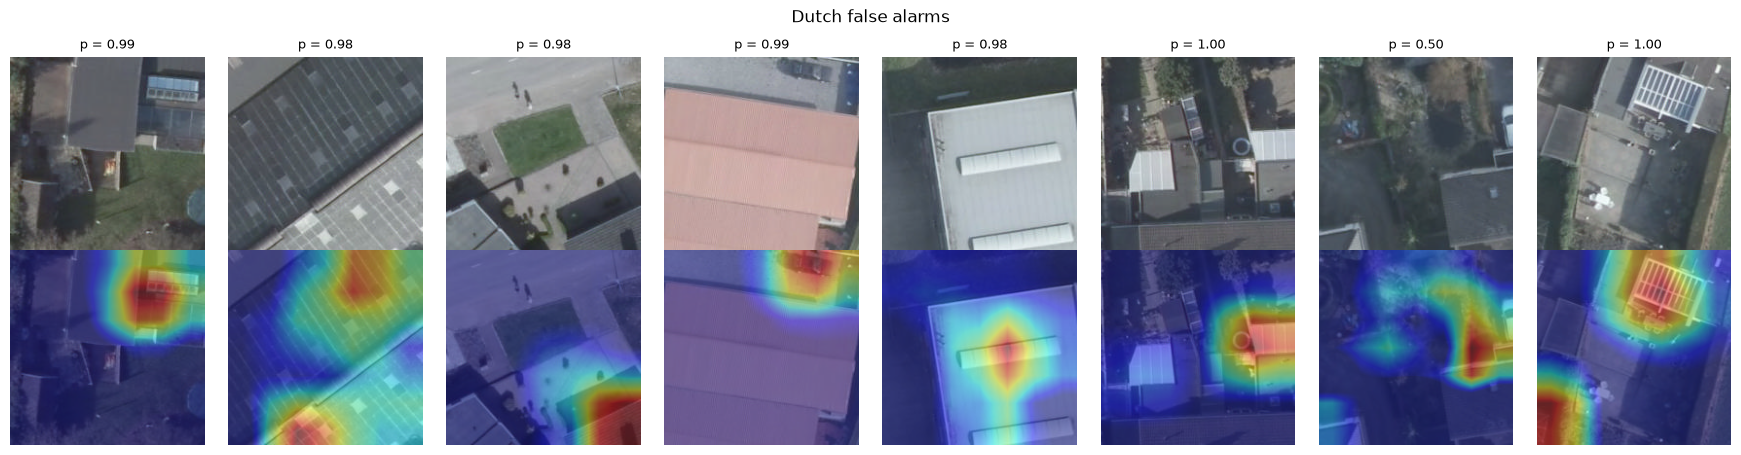

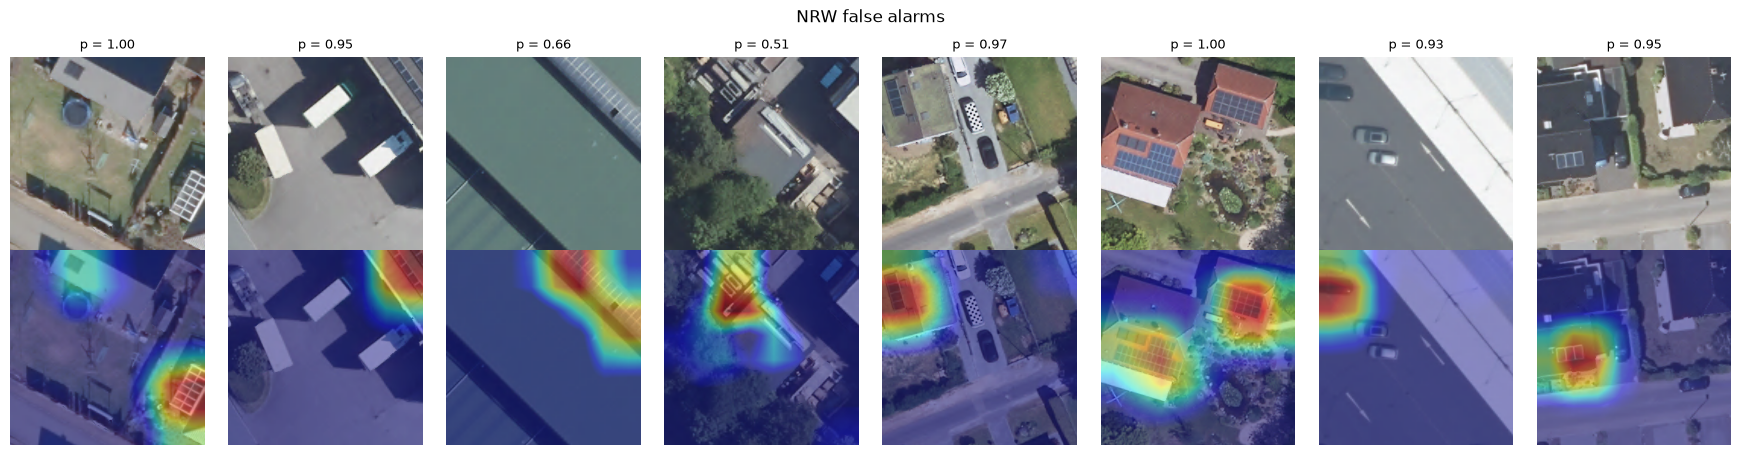

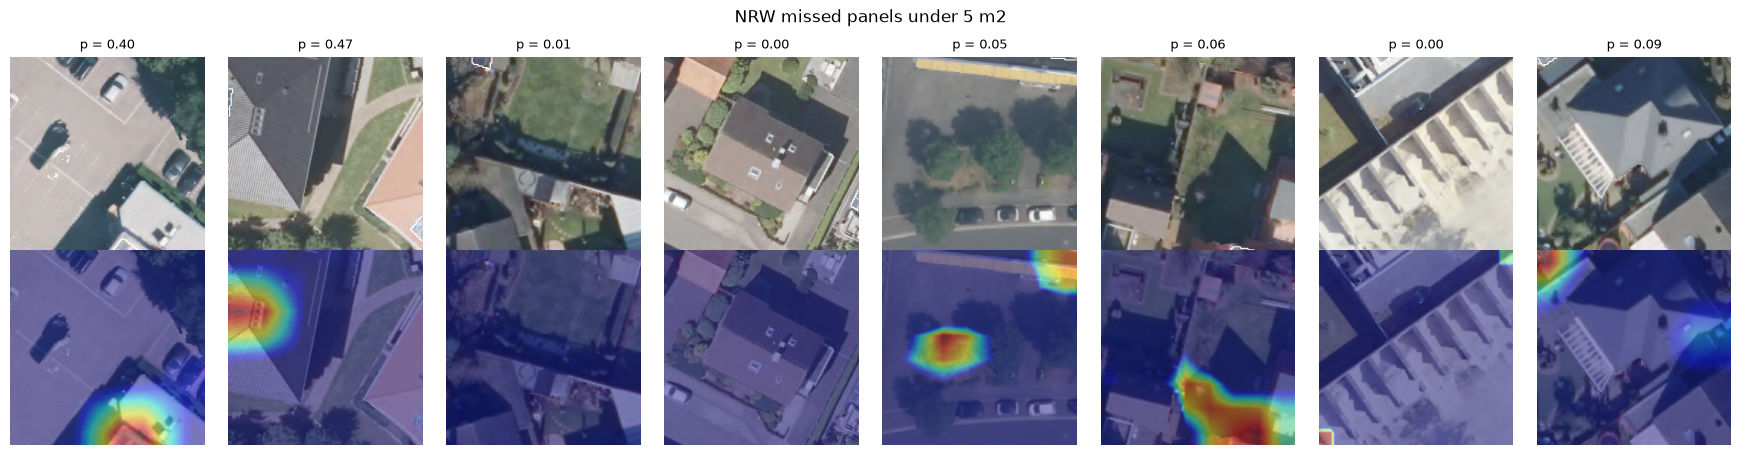

In [13]:
def show_cams(df, loader_fn, title, n=8, seed=0, masks=False):
    pick = df.sample(min(n, len(df)), random_state=seed)
    if not len(pick):
        print(title, "- no examples"); return
    x, *rest = next(iter(loader_fn(pick, len(pick))))
    p, cams = gc(x.to(DEVICE))
    img = (x.permute(0, 2, 3, 1).numpy() * IMAGENET_STD + IMAGENET_MEAN).clip(0, 1)
    fig, ax = plt.subplots(2, len(pick), figsize=(2.2 * len(pick), 4.6))
    ax = np.atleast_2d(ax).reshape(2, -1)
    for j in range(len(pick)):
        ax[0, j].imshow(img[j]); ax[0, j].set_title(f"p = {p[j]:.2f}", fontsize=9)
        ax[1, j].imshow(img[j]); ax[1, j].imshow(np.clip(cams[j], 0, None), cmap="jet", alpha=0.45)
        if masks:
            ax[0, j].contour(rest[0][j].numpy() > 0, levels=[0.5], colors="white", linewidths=0.8)
        for a in ax[:, j]:
            a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()


show_cams(cam_nl[(cam_nl.fraction == 0) & (cam_nl.prob >= 0.5)], nl_loader, "Dutch false alarms")
show_cams(cam_nrw[(cam_nrw.label == 0) & cam_nrw.found], nrw_loader, "NRW false alarms")
show_cams(cam_nrw[(cam_nrw.label == 1) & ~cam_nrw.found & (cam_nrw["size"] == "under 5 m2")], nrw_loader,
          "NRW missed panels under 5 m2", masks=True)

**Was sich zeigte.**

* **Findet der Klassifikator eine Anlage, betrachtet er sie auch.** In 86–97 % der Treffer, je nach Größe, liegt der stärkste Punkt der Karte auf der Anlage.
* **Übersehene kleine Anlagen werden oft gar nicht beachtet.** Bei übersehenen Anlagen unter 5 m² liegt die Spitze nur in 46 % der Fälle auf der Anlage (n = 26). In etwa der Hälfte dieser Fälle sieht das Modell die Anlage nicht. Eine niedrigere Schwelle allein kann sie nicht zurückgewinnen.
* **Fehlalarme gehen von einzelnen Objekten aus.** Der Anteil der Karte in ihren stärksten 10 % ist bei Fehlalarmen höher als bei Treffern: 0,56 gegenüber 0,48 auf NRW, 0,60–0,61 gegenüber 0,46–0,48 auf den niederländischen Kacheln. Das Modell reagiert auf ein anlagenähnliches Objekt, nicht auf die Umgebung.
* **Die Beispiele zeigen, auf welche Objekte.**
  * Niederländische Fehlalarme: Gewächshäuser und Wintergärten, Lichtbänder auf Flachdächern, eine Glaspergola, Reihen dunkler Dachziegel.
  * NRW-Fehlalarme: Mehrere Beispiele zeigen Objekte die aussehen wie Solaranlagen, die aber in der Maske fehlen. Ein Teil der NRW-„Fehlalarme“ könnten also Lücken in den Referenzdaten sein, keine Modellfehler.
  * Übersehene kleine Anlagen: In den meisten Beispielen liegt der Maskenumriss am Rand des Ausschnitts, sodass nur ein Teil der Anlage sichtbar ist.

**Folge für die nächsten Schritte.** Das Modell scheitert an zwei Dingen, die unterschiedliche Abhilfen brauchen. Es verwechselt Anlagen mit anlagenähnlichen Objekten, was feinere Details im Kontext verlangt (Schritt 5). Und es übersieht kleine Anlagen, die es nicht beachtet, was ein Trainingssignal verlangt, bei dem kleine Anlagen nicht untergehen (Schritt 6).

**Was es nicht zeigt.** Grad-CAM erklärt den Klassifikator, nicht die später verwendeten U-Nets. Bei 3,2 m je Zelle füllt eine Anlage unter 5 m² eine einzige Zelle, „Spitze auf der Anlage“ ist also gerade für diese Gruppe grob. Es sind acht Beispiele je Gruppe, zufällig, aber wenige. Die gezeigten Labellücken wurden nicht systematisch gezählt; der Bewertungsbogen in `review_solar/` ist dafür vorbereitet, aber noch nicht ausgefüllt.

## Schritt 5 · Hypothese: U-Net++ verallgemeinert besser auf neue Dächer

**Frage.** Gehen die Fehlalarme von anlagenähnlichen Objekten auf Dächern aus, muss das Modell feine Details in ihrem Kontext unterscheiden: Ein Dachfenster und eine kleine Anlage unterscheiden sich in Textur, Rahmen und in der Art, wie sie auf dem Dach liegen. U-Net++ verbindet auf jeder Decoderebene Merkmale mehrerer Maßstäbe. Die Hypothese lautet, dass es solche Objekte auf nie gesehenen Dächern besser trennt.

**Aufbau.** U-Net++ gegen U-Net, mit gleicher Verlustfunktion und gleichem Rezept. Entscheidend ist der Test auf den niederländischen Kacheln: ein neues Land mit anderen Dächern, nie zum Training verwendet, die Schwelle auf NRW eingefroren.

In [14]:
RUNS["U-Net++"] = train_or_load("unetpp_ce_dice_s21", "unetpp", "ce_dice")
scores("U-Net++", *RUNS["U-Net++"])
summary(["U-Net", "U-Net++"])

unetpp_ce_dice_s21: loaded existing checkpoint (29.10.2026), not retrained


,AUC,hit rate,precision,under 5 m2,"test FA /1,000","NL FA /1,000 Heerlen","NL FA /1,000 Zuid-Limburg"
U-Net,0.974,0.878,0.798,0.583,41.469,204.522,153.903
U-Net++,0.977,0.892,0.797,0.646,42.358,206.301,157.412


**Was sich zeigte.** **Die Hypothese bestätigt sich nicht.** Auf den niederländischen Kacheln, dem entscheidenden Test, erzeugt U-Net++ 206 und 157 Fehlalarme je 1 000, das U-Net 205 und 154: keine Verbesserung. Auf NRW findet es etwas mehr kleine Anlagen (65 % gegenüber 58 %), doch die Intervalle überlappen stark (n = 48). Die zusätzlichen Verbindungen über mehrere Maßstäbe haben dem Modell nicht beigebracht, Anlagen in einem neuen Land von anlagenähnlichen Dachobjekten zu unterscheiden.

**Was es nicht zeigt.** Dass U-Net++ nicht besser verallgemeinern kann. Es gibt nur einen Startwert je Modell, und Schritt 6 zeigt, dass allein der Startwert die niederländische Fehlalarmquote um etwa 40 je 1 000 verschiebt. Kleinere Unterschiede sind mit diesem Aufbau nicht nachweisbar.

## Schritt 6 · Eine Verlustfunktion, die jede Anlage zählt (Blob-Dice)

**Frage.** Die Schwäche bei kleinen Anlagen aus den Schritten 1–3 ist noch offen. Der zusammengefasste Dice-Verlust lässt große Anlagen dominieren. Findet eine Verlustfunktion, die jede Anlage gleich gewichtet, mehr kleine Anlagen? Ist der Gewinn stabil oder ein glücklicher Einzellauf?

**Aufbau.**

* **2 × 2:** Architektur (U-Net / U-Net++) × Verlust (`ce_dice` / `blob`), damit sich der Effekt der Verlustfunktion vom Effekt der Architektur trennen lässt.
* **Wiederholungen:** U-Net++ mit Blob-Dice wird mit drei Startwerten trainiert. Die räumliche Aufteilung bleibt fest, die Läufe unterscheiden sich also nur in der Zufälligkeit des Trainings (Initialisierung der Gewichte und Stichprobenziehung).
* **Was zählt:** Ein Teilgruppenergebnis zählt nur, wenn es über die Startwerte hinweg hält und sein Intervall eng genug ist, um eine Rolle zu spielen.

In [15]:
RUNS["U-Net blob"] = train_or_load("unet_blob_s21", "unet", "blob")
scores("U-Net blob", *RUNS["U-Net blob"])
for s in SEEDS:
    RUNS[f"U-Net++ blob s{s}"] = train_or_load(f"unetpp_blob_s{s}", "unetpp", "blob", seed=s)
    scores(f"U-Net++ blob s{s}", *RUNS[f"U-Net++ blob s{s}"])
blob_seeds = [f"U-Net++ blob s{s}" for s in SEEDS]

table = summary(["U-Net", "U-Net++", "U-Net blob"] + blob_seeds)
display(table)
print("U-Net++ blob, spread over seeds:")
display(seed_spread(table.loc[blob_seeds]))
display(strata_table(["U-Net", "U-Net blob"] + blob_seeds, "size"))
display(strata_table(["U-Net", "U-Net blob"] + blob_seeds, "type"))
display(strata_table(["U-Net", "U-Net blob"] + blob_seeds, "year"))

unet_blob_s21: trained 20 epochs, best validation tile F1 0.840 (epoch 17)


unetpp_blob_s21: loaded existing checkpoint (29.10.2026), not retrained


unetpp_blob_s7: loaded existing checkpoint (30.10.2026), not retrained


unetpp_blob_s42: loaded existing checkpoint (30.10.2026), not retrained


,AUC,hit rate,precision,under 5 m2,"test FA /1,000","NL FA /1,000 Heerlen","NL FA /1,000 Zuid-Limburg"
U-Net,0.974,0.878,0.798,0.583,41.469,204.522,153.903
U-Net++,0.977,0.892,0.797,0.646,42.358,206.301,157.412
U-Net blob,0.981,0.917,0.789,0.792,45.912,164.172,120.603
U-Net++ blob s21,0.985,0.957,0.781,0.854,50.059,165.323,118.154
U-Net++ blob s7,0.983,0.938,0.792,0.812,45.912,190.234,139.103
U-Net++ blob s42,0.981,0.924,0.795,0.812,44.431,151.193,111.979


U-Net++ blob, spread over seeds:


,min,max
AUC,0.981,0.985
hit rate,0.924,0.957
precision,0.781,0.795
under 5 m2,0.812,0.854
"test FA /1,000",44.431,50.059
"NL FA /1,000 Heerlen",151.193,190.234
"NL FA /1,000 Zuid-Limburg",111.979,139.103


,n,U-Net,U-Net blob,U-Net++ blob s21,U-Net++ blob s7,U-Net++ blob s42
size,,,,,,
under 5 m2,48,0.58 [0.44-0.71],0.79 [0.66-0.88],0.85 [0.73-0.93],0.81 [0.68-0.90],0.81 [0.68-0.90]
5-20 m2,119,0.85 [0.77-0.90],0.87 [0.79-0.92],0.87 [0.80-0.92],0.92 [0.86-0.96],0.92 [0.85-0.95]
20-50 m2,144,0.94 [0.89-0.97],0.97 [0.92-0.99],0.98 [0.94-0.99],0.97 [0.93-0.99],0.97 [0.92-0.99]
50-200 m2,207,0.92 [0.88-0.95],0.94 [0.90-0.97],0.99 [0.97-1.00],0.98 [0.94-0.99],0.94 [0.90-0.97]
over 200 m2,112,0.88 [0.80-0.92],0.92 [0.85-0.96],1.00 [0.97-1.00],0.89 [0.82-0.94],0.89 [0.82-0.94]


,n,U-Net,U-Net blob,U-Net++ blob s21,U-Net++ blob s7,U-Net++ blob s42
type,,,,,,
both,3,0.67 [0.21-0.94],0.67 [0.21-0.94],1.00 [0.44-1.00],1.00 [0.44-1.00],0.67 [0.21-0.94]
ground only,42,0.69 [0.54-0.81],0.81 [0.67-0.90],0.93 [0.81-0.98],0.98 [0.88-1.00],0.79 [0.64-0.88]
rooftop only,585,0.89 [0.86-0.91],0.93 [0.90-0.94],0.96 [0.94-0.97],0.94 [0.91-0.95],0.94 [0.91-0.95]


,n,U-Net,U-Net blob,U-Net++ blob s21,U-Net++ blob s7,U-Net++ blob s42
year,,,,,,
2022,203,0.83 [0.78-0.88],0.89 [0.84-0.92],0.91 [0.86-0.94],0.95 [0.91-0.97],0.91 [0.86-0.94]
2023,122,0.80 [0.71-0.86],0.85 [0.78-0.90],0.98 [0.94-1.00],0.84 [0.77-0.90],0.83 [0.75-0.88]
2024,305,0.94 [0.91-0.96],0.96 [0.94-0.98],0.98 [0.95-0.99],0.97 [0.94-0.98],0.97 [0.95-0.99]


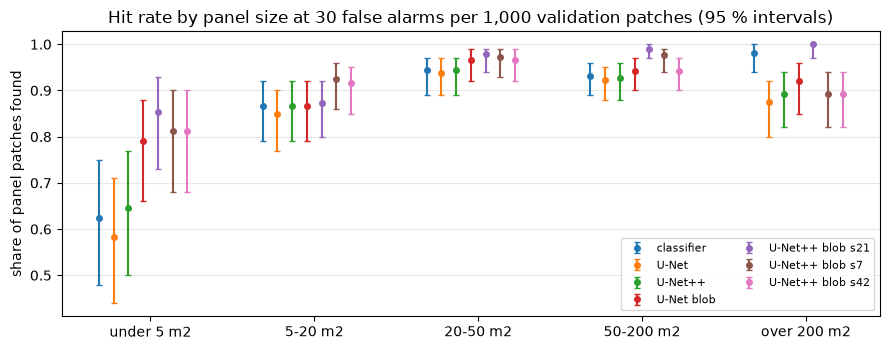

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.6))
names = ["classifier", "U-Net", "U-Net++", "U-Net blob"] + blob_seeds
for i, n in enumerate(names):
    st = result(n)["strata"]["size"]
    xs = np.arange(len(AREA_LABELS)) + (i - len(names) / 2) * 0.09
    h = [st.get(k, {}).get("hit_rate", np.nan) for k in AREA_LABELS]
    lo = [h_ - st.get(k, {}).get("ci95", (np.nan,))[0] for h_, k in zip(h, AREA_LABELS)]
    hi = [st.get(k, {}).get("ci95", (0, np.nan))[1] - h_ for h_, k in zip(h, AREA_LABELS)]
    ax.errorbar(xs, h, yerr=[lo, hi], fmt="o", ms=4, capsize=2, label=n)
ax.set_xticks(range(len(AREA_LABELS)), AREA_LABELS); ax.set_ylabel("share of panel patches found")
ax.set_title(f"Hit rate by panel size at {FA_TARGET:g} false alarms per 1,000 validation patches (95 % intervals)")
ax.legend(fontsize=8, ncol=2, loc="lower right"); ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

**Was sich zeigte.**

* **Die Verlustfunktion wirkt stärker als die Architektur.**
  * Blob-Dice hebt beim U-Net die Trefferquote für Anlagen unter 5 m² von 58 % auf 79 %.
  * Bei U-Net++ erreicht sie 81–85 % über drei Startwerte, gegenüber 65 % für U-Net++ ohne Blob-Dice.
  * Ein Wechsel der Architektur bei fester Verlustfunktion verschiebt die Ergebnisse weniger als die Startwerte.
* **Unerwartet verbesserte sich auch die Übertragbarkeit.** Das U-Net mit Blob-Dice erzeugt 164 und 121 Fehlalarme je 1 000 niederländische Kacheln, ohne Blob-Dice 205 und 154. Die Hypothese aus Schritt 5, dass die Architektur die Übertragbarkeit verbessert, bestätigte sich nicht; die geänderte Verlustfunktion verbesserte sie, obwohl sie für kleine Anlagen eingeführt wurde.
* **Der Gewinn bei kleinen Anlagen ist über Startwerte stabil, andere Teilgruppen sind es nicht.**
  * Unter 5 m² liegen alle drei U-Net++-Blob-Läufe bei 81–85 %.
  * Über 200 m² reicht die Trefferquote von 89 % bis 100 %.
  * Für das Befliegungsjahr 2023 reicht sie von 83 % bis 98 %.
  * Auf niederländischen Kacheln reichen die Fehlalarme von 151 bis 190 je 1 000.
  * Ein einzelner Lauf (Startwert 21) hätte einen großen Architektureffekt bei großen Anlagen und Bildern von 2023 nahegelegt. Mit drei Startwerten liegt dieser Effekt innerhalb der Streuung.
* **Auf der Testmenge überschreitet jedes Modell das Validierungsbudget:** 41–50 statt 30 Fehlalarme je 1 000. Die Überschreitung ist bei allen Modellen ähnlich, der Vergleich bleibt also fair. Für die Praxis heißt das: Eine auf Validierungsdaten gesetzte Schwelle unterschätzt den Prüfaufwand.

**Was es nicht zeigt.** Das 2 × 2 hat je Zelle nur einen Startwert, außer bei U-Net++ mit Blob-Dice. Die Aussage „Verlustfunktion vor Architektur“ stützt sich auf die Größe des Effekts (+21 Prozentpunkte bei kleinen Anlagen, mehr als die Streuung von 4 Punkten über Startwerte), nicht auf Wiederholungen jeder Zelle. Der U-Net-Blob-Lauf ist der in diesem Notebook neu trainierte (beste Epoche 17 von 20).

## Schritt 7 · Wahl des Arbeitspunkts

Bis hierher wurden alle Modelle beim gleichen Fehlalarmbudget verglichen; nur so ist ein Modellvergleich fair. Für den Einsatz in einem statistischen Amt ist das Budget eine Wahl, und die beiden Fehler kosten nicht dasselbe, wenn Anlagen gefunden werden sollen, die in einem Register fehlen:

* ein Fehlalarm kostet einen Blick auf ein Bild;
* eine übersehene Anlage wird nie angesehen und fehlt in jeder Vollständigkeitsprüfung. Das Marktstammdatenregister veröffentlicht die Standorte kleiner Anlagen nicht; eine unabhängige Zählung ist daher einer der wenigen Wege, es zu prüfen.

Das gewählte Modell, U-Net++ mit Blob-Dice über alle Startwerte, läuft deshalb mit einem höheren, vorab festgelegten Budget: `FA_FINAL` Fehlalarme je 1 000 Validierungsausschnitte statt 30. In der Praxis ergibt sich das Budget daraus, wie viele Bilder das Personal prüfen kann. Die Tabelle zeigt, was die zusätzlichen Fehlalarme bringen, aufgeschlüsselt nach Anlagengröße.

In [17]:
low, high = summary(blob_seeds, FA_TARGET), summary(blob_seeds, FA_FINAL)
cmp = pd.concat({f"budget {FA_TARGET:g}": seed_spread(low), f"budget {FA_FINAL:g}": seed_spread(high)}, axis=1)
display(cmp)
size_low = {n: result(n, FA_TARGET)["strata"]["size"] for n in blob_seeds}
size_high = {n: result(n, FA_FINAL)["strata"]["size"] for n in blob_seeds}
pd.DataFrame({k: {f"budget {FA_TARGET:g}": f"{min(size_low[n][k]['hit_rate'] for n in blob_seeds):.2f}-{max(size_low[n][k]['hit_rate'] for n in blob_seeds):.2f}",
                  f"budget {FA_FINAL:g}": f"{min(size_high[n][k]['hit_rate'] for n in blob_seeds):.2f}-{max(size_high[n][k]['hit_rate'] for n in blob_seeds):.2f}"}
              for k in AREA_LABELS if k in size_low[blob_seeds[0]]}).T.rename_axis("hit rate by size (min-max over seeds)")

budget 30          budget 60         
                                min      max       min      max
AUC                           0.981    0.985     0.981    0.985
hit rate                      0.924    0.957     0.954    0.976
precision                     0.781    0.795     0.681    0.703
under 5 m2                    0.812    0.854     0.917    0.958
test FA /1,000               44.431   50.059    76.422   85.308
NL FA /1,000 Heerlen        151.193  190.234   238.434  270.567
NL FA /1,000 Zuid-Limburg   111.979  139.103   173.273  199.663

,budget 30,budget 60
hit rate by size (min-max over seeds),,
under 5 m2,0.81-0.85,0.92-0.96
5-20 m2,0.87-0.92,0.92-0.96
20-50 m2,0.97-0.98,0.97-0.99
50-200 m2,0.94-0.99,0.96-1.00
over 200 m2,0.89-1.00,0.95-1.00


**Was sich zeigte.** Eine Verdopplung des Budgets von 30 auf 60 Fehlalarme je 1 000 Validierungsausschnitte bringt fast nur kleine Anlagen:

* **Anlagen unter 5 m²:** zu 92–96 % gefunden statt zu 81–85 %. Von den 48 kleinen Testanlagen werden 2–4 übersehen statt 7–9.
* **Anlagen ab 20 m²:** ändern sich kaum, weil sie schon gefunden wurden.
* **Der Preis:**
  * Die Präzision sinkt von 0,78–0,80 auf 0,68–0,70.
  * Die Fehlalarme auf der Testmenge steigen von 44–50 auf 76–85 je 1 000 Ausschnitte.
  * Auf niederländischen Kacheln steigen die Fehlalarme auf 238–271 und 173–200 je 1 000.

Für eine Registerprüfung ist das der bessere Tausch: Ein Fehlalarm kostet einen Blick auf ein Bild, eine übersehene Anlage fehlt in jeder Vollständigkeitsprüfung.

**Was es nicht zeigt.** Welches Budget sich ein Amt leisten kann. Das hängt von der Prüfzeit je Bild ab und davon, wie viele Ausschnitte eine Region hat. Ein Teil der „Fehlalarme“ sind Anlagen, die in den Referenzmasken fehlen (Schritt 4). Die tatsächliche Präzision liegt daher etwas höher als gemessen, um einen noch unbekannten Betrag.

## Zusammenfassung

1. **Die Pipeline ist belastbar.** Die veröffentlichten Werte werden reproduziert (F1 0,967); spätere Unterschiede sind also keine Fehler der eigenen Vorverarbeitung.
2. **Kleine Anlagen sind eine Schwäche des Ansatzes, nicht des Landes.** Das veröffentlichte Modell findet auf NRW 35 % der Anlagen unter 5 m². Auf NRW neu trainiert findet es 62 %, ein U-Net 58 %. Anlagen ab 20 m² werden durchgehend zu über 90 % gefunden.
3. **Grad-CAM teilte das Problem in zwei.**
   * Übersehene kleine Anlagen werden oft gar nicht beachtet.
   * Fehlalarme gehen von einzelnen anlagenähnlichen Objekten aus: Gewächshäusern, Dachfenstern, Glasdächern.
   * Außerdem zeigte sich, dass manche NRW-„Fehlalarme“ Anlagen sind, die in den Referenzmasken fehlen.
4. **Die Architekturhypothese wurde geprüft und nicht bestätigt.** U-Net++ senkte die niederländischen Fehlalarme nicht.
5. **Die geänderte Verlustfunktion wirkte, und breiter als beabsichtigt.** Blob-Dice hob die Trefferquote bei kleinen Anlagen auf 81–85 %, stabil über drei Startwerte, und senkte zudem die niederländischen Fehlalarme.
6. **Drei Startwerte änderten die Lesart.** Mehrere Unterschiede, die ein Einzellauf als Befund gemeldet hätte, liegen innerhalb der Streuung.
7. **Der Arbeitspunkt ist eine Entscheidung.** Um Anlagen zu finden, die in einem Register fehlen, findet ein Budget von 60 Fehlalarmen je 1 000 92–96 % der kleinen Anlagen. Der Preis sind etwa 35 zusätzlich zu prüfende Bilder je 1 000.

**Grenzen.**

* Die Gruppe der kleinen Anlagen umfasst 48 Testanlagen, die Intervalle sind daher breit.
* Die niederländischen Kacheln haben keine Größenlabels; die Übertragbarkeit wird nur über Fehlalarme gemessen.
* Die Referenzmasken selbst haben Lücken.
* Alle Ergebnisse stammen aus einer Region in NRW und vier Befliegungsjahren.

**Nächste Schritte.**

* Ausgeschnittene Anlagen und Fehlalarm-Objekte klassifizieren: Lassen die Daten eine Unterscheidung überhaupt zu?
* Labellücken systematisch zählen (Bewertungsbogen in `review_solar/`).
* Größere oder überlappende Ausschnitte testen, damit kleine Anlagen am Rand vollständig sichtbar sind.
* Eine Klasse schwieriger Negativbeispiele für Gewächshäuser und Dachfenster ergänzen.